### **Linear Regression - Machine Learning Algoritham**

In [94]:
# Step 1 => Read the data

import pandas as pd
odi_info = pd.read_csv("C:\\Gen AI Course Details\\Machine Learning CSV files\\india_odi_linear_regression_data.csv")
odi_info

,match_id,opponent,venue,powerplay_runs,fours,sixes,wickets_lost,total_score
0,1,Afghanistan,Away,71,22,11,3,294
1,2,Sri Lanka,Away,39,31,15,6,270
2,3,Bangladesh,Away,55,19,13,9,247
3,4,Afghanistan,Away,65,18,4,7,216
4,5,Sri Lanka,Home,37,37,12,2,280
...,...,...,...,...,...,...,...,...
145,146,West Indies,Away,73,40,11,4,342
146,147,Australia,Home,39,40,3,4,265
147,148,Sri Lanka,Away,70,39,9,6,309
148,149,New Zealand,Away,62,20,7,3,249


In [95]:
odi_info.columns = odi_info.columns.str.lower()
odi_info

,match_id,opponent,venue,powerplay_runs,fours,sixes,wickets_lost,total_score
0,1,Afghanistan,Away,71,22,11,3,294
1,2,Sri Lanka,Away,39,31,15,6,270
2,3,Bangladesh,Away,55,19,13,9,247
3,4,Afghanistan,Away,65,18,4,7,216
4,5,Sri Lanka,Home,37,37,12,2,280
...,...,...,...,...,...,...,...,...
145,146,West Indies,Away,73,40,11,4,342
146,147,Australia,Home,39,40,3,4,265
147,148,Sri Lanka,Away,70,39,9,6,309
148,149,New Zealand,Away,62,20,7,3,249


In [96]:
# Step 2 => Understand the data

odi_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   match_id        150 non-null    int64
 1   opponent        150 non-null    str  
 2   venue           150 non-null    str  
 3   powerplay_runs  150 non-null    int64
 4   fours           150 non-null    int64
 5   sixes           150 non-null    int64
 6   wickets_lost    150 non-null    int64
 7   total_score     150 non-null    int64
dtypes: int64(6), str(2)
memory usage: 9.5 KB


In [97]:
odi_info.isna().sum()

match_id          0
opponent          0
venue             0
powerplay_runs    0
fours             0
sixes             0
wickets_lost      0
total_score       0
dtype: int64

In [98]:
odi_info.describe()

,match_id,powerplay_runs,fours,sixes,wickets_lost,total_score
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,58.073333,26.606667,9.046667,6.000000,259.353333
std,43.445368,12.950135,8.166799,4.065465,2.308432,39.404653
min,1.000000,35.000000,14.000000,2.000000,2.000000,151.000000
25%,38.250000,46.250000,19.250000,6.000000,4.000000,230.250000
50%,75.500000,59.000000,26.000000,9.000000,6.000000,262.500000
75%,112.750000,69.000000,34.000000,12.750000,8.000000,286.250000
max,150.000000,80.000000,40.000000,15.000000,10.000000,356.000000


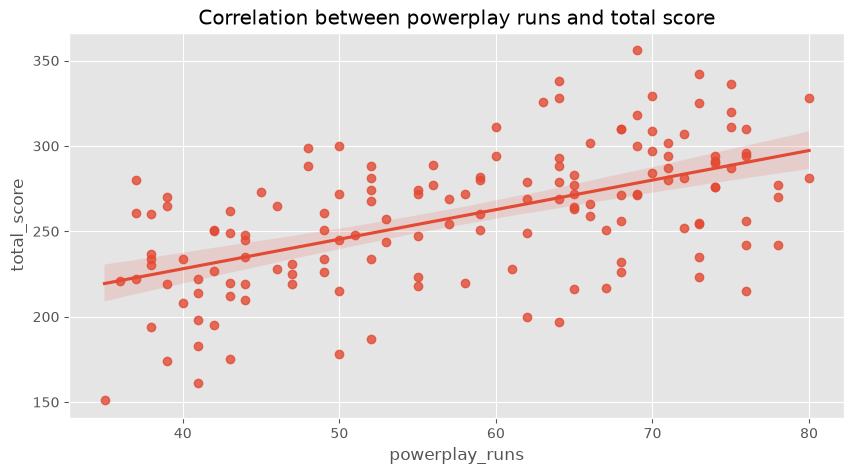

In [99]:
# Step 3 => Check the relation between powerplay runs and total score

plt.figure(figsize=(10, 5))
plt.title("Correlation between powerplay runs and total score")
sns.regplot(x=odi_info["powerplay_runs"], y=odi_info["total_score"])
plt.show()

In [100]:
# Step 4 => Input and output data

X = odi_info.drop(columns=["match_id", "total_score"])
y = odi_info["total_score"]

In [101]:
# Step 5 => Convert categorical columns (opponent, venue) to numbers

X = pd.get_dummies(X, dtype=int)

In [102]:
# Step 6 => Scale the input data

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
input_data = scaler.fit_transform(input_data)

In [103]:
# Step 7 => Split into train and test data

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state = 42)

In [104]:
# Step 8 => Train the model

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[ 1.98, 2.92, 3.97,...,-0.39,-4.93, 4.93]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['powerplay_runs','fours','sixes',...,'opponent_West Indies','venue_Away', 'venue_Home']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.74
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [105]:
# Step 9 => Predict the total score

predicted_total_score = model.predict(X_test)
print(predicted_total_score)

[319.26392574 200.40418275 237.50068092 256.93275316 212.38227727
 280.80342319 282.70318249 272.29312671 291.7633137  267.22611665
 279.75265223 230.74547283 326.8577359  309.01599044 247.02378857
 233.75359591 270.33857061 300.10015426 242.31867392 326.53295247
 280.43548932 268.00902553 224.00417456 305.13096899 222.32340379
 340.85428687 281.72631496 277.99820809 264.95427835 266.94481769]


In [106]:
# Step 10 => Check the errors

from sklearn import metrics
print("Mean absolute error:", metrics.mean_absolute_error(y_test, predicted_total_score))
print("Mean squared error :", metrics.mean_squared_error(y_test, predicted_total_score))

Mean absolute error: 6.427070693604218
Mean squared error : 66.58276325528344
